## Ice Task 3 PDAN8412

Comparing a simple RNN and a GRU for sentiment analysis on the IMDB movie review dataset. Both models are tuned by changing the number of hidden layers, the number of epochs and the batch size, and then the best version of each is tested on the test set.

Dataset: IMDB Dataset of 50K Movie Reviews from Kaggle (https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews)

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import tensorflow as tf #imported before pandas, the other way round made training freeze on this laptop

import re
import time
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, GRU, Dense
from tensorflow.keras.callbacks import Callback

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

#Run on the CPU. On this Mac the GPU gave no speed up for these models and caused errors when resetting the seed
tf.config.set_visible_devices([], "GPU")

In [2]:
#Fix the random seeds so the results can be repeated
seed = 42
tf.keras.utils.set_random_seed(seed) #sets the seed for python, numpy and tensorflow

pd.set_option("display.max_colwidth", 200)

### Loading and exploring the data

In [3]:
df = pd.read_csv("IMDB Dataset.csv")
df.head()

,review,sentiment
0,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me...",positive
1,"A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire p...",positive
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater and watching a light-hearted comedy. The plot is simplistic, but the dialogue i...",positive
3,Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />This movie is slower than a soap opera... and suddenl...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is a visually stunning film to watch. Mr. Mattei offers us a vivid portrait about human relations. This is a movie that seems to be telling us what mone...",positive


In [4]:
print(df.shape)
df.info()

(50000, 2)
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB


sentiment
positive    25000
negative    25000
Name: count, dtype: int64


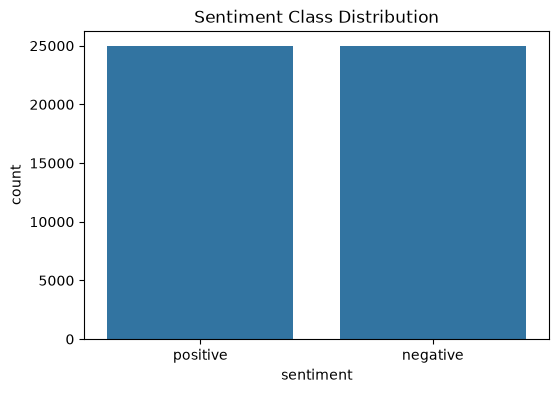

In [5]:
print(df['sentiment'].value_counts())

plt.figure(figsize = (6, 4))
sns.countplot(data = df, x = "sentiment")
plt.title("Sentiment Class Distribution")
plt.show()

In [6]:
print("Missing values:")
print(df.isnull().sum())

print("Duplicate reviews:", df['review'].duplicated().sum())

Missing values:
review       0
sentiment    0
dtype: int64
Duplicate reviews: 418


In [7]:
#Remove the duplicate reviews so the same review can't end up in both the training and test set
df = df.drop_duplicates(subset = ["review"], keep = "first")
print(df.shape)

(49582, 2)


count    49582.000000
mean       231.350167
std        171.542020
min          4.000000
25%        126.000000
50%        173.000000
75%        281.000000
max       2470.000000
Name: word_count, dtype: float64


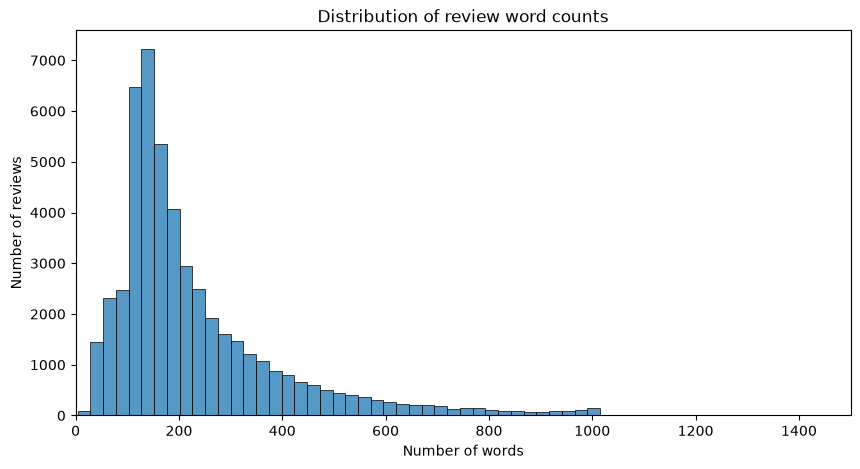

In [8]:
df["word_count"] = df["review"].apply(lambda x: len(x.split()))
print(df["word_count"].describe())

plt.figure(figsize = (10, 5))
sns.histplot(data = df, x = "word_count", bins = 100)
plt.xlim(0, 1500)
plt.title("Distribution of review word counts")
plt.xlabel("Number of words")
plt.ylabel("Number of reviews")
plt.show()

### Cleaning the text

The reviews were scraped from a website so they still have html line breaks like `<br />` in them. These are removed along with anything that isn't a letter or an apostrophe, and everything is made lowercase.

In [9]:
def clean_review(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text) #remove html tags
    text = re.sub(r"[^a-z' ]", " ", text) #keep only letters and apostrophes
    text = re.sub(r"\s+", " ", text) #remove extra spaces
    return text.strip()

df["clean_review"] = df["review"].apply(clean_review)
df[["review", "clean_review"]].head(3)

,review,clean_review
0,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me...",one of the other reviewers has mentioned that after watching just oz episode you'll be hooked they are right as this is exactly what happened with me the first thing that struck me about oz was it...
1,"A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire p...",a wonderful little production the filming technique is very unassuming very old time bbc fashion and gives a comforting and sometimes discomforting sense of realism to the entire piece the actors ...
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater and watching a light-hearted comedy. The plot is simplistic, but the dialogue i...",i thought this was a wonderful way to spend time on a too hot summer weekend sitting in the air conditioned theater and watching a light hearted comedy the plot is simplistic but the dialogue is w...


In [10]:
#Positive = 1 and Negative = 0
df["label"] = (df["sentiment"] == "positive").astype(int)
df[["sentiment", "label"]].head()

,sentiment,label
0,positive,1
1,positive,1
2,positive,1
3,negative,0
4,positive,1


### Splitting the data

Same as in class, 30% is kept aside as the test set and then 20% of what is left is used as the validation set. The validation set is used to compare the hyperparameter settings and the test set is only used once at the very end.

In [11]:
x = df["clean_review"]
y = df["label"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.3, random_state = seed, stratify = y)
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size = 0.2, random_state = seed, stratify = y_train)

print("Training:", len(x_train))
print("Validation:", len(x_val))
print("Test:", len(x_test))

Training: 27765
Validation: 6942
Test: 14875


### Tokenizing and padding

In [12]:
#Only keep the 10000 most common words, anything else becomes <OOV>
max_words = 10000
tokenizer = Tokenizer(num_words = max_words, oov_token = "<OOV>")
tokenizer.fit_on_texts(x_train)

print("Unique words found:", len(tokenizer.word_index))

x_train_seq = tokenizer.texts_to_sequences(x_train)
x_val_seq = tokenizer.texts_to_sequences(x_val)
x_test_seq = tokenizer.texts_to_sequences(x_test)

Unique words found: 92391


In [13]:
sequence_lengths = [len(s) for s in x_train_seq]
print(pd.Series(sequence_lengths).describe())
print("Reviews with 200 words or less:", round(np.mean(np.array(sequence_lengths) <= 200) * 100, 1), "%")

count    27765.000000
mean       230.529552
std        171.167090
min          6.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2462.000000
dtype: float64
Reviews with 200 words or less: 59.2 %


The reviews are cut or padded to 200 words. Pre padding is used, which means the zeros go at the start of the review. An RNN reads left to right and its final output is what gets passed to the Dense layer, so if the zeros came after the review the model would have to remember the review through a long run of empty padding. With pre padding the real words are the last thing it reads.

In [14]:
max_length = 200
x_train = pad_sequences(x_train_seq, maxlen = max_length, padding = "pre", truncating = "post")
x_val = pad_sequences(x_val_seq, maxlen = max_length, padding = "pre", truncating = "post")
x_test = pad_sequences(x_test_seq, maxlen = max_length, padding = "pre", truncating = "post")

y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)

print(x_train.shape, x_val.shape, x_test.shape)

(27765, 200) (6942, 200) (14875, 200)


### Building the models

One function builds both models. It has an embedding layer, then the chosen number of SimpleRNN or GRU layers with 64 units each, and a Dense layer with one neuron and a sigmoid activation for the binary positive or negative output. When layers are stacked, every recurrent layer except the last one needs `return_sequences = True` so it passes its output for every word on to the next layer, instead of only its final output.

In [15]:
def build_model(model_type, hidden_layers):
    model = Sequential()
    model.add(Input(shape = (max_length,)))
    model.add(Embedding(input_dim = max_words, output_dim = 64))

    for i in range(hidden_layers):
        last_layer = (i == hidden_layers - 1)
        if model_type == "RNN":
            model.add(SimpleRNN(64, return_sequences = not last_layer))
        else:
            model.add(GRU(64, return_sequences = not last_layer))

    model.add(Dense(1, activation = "sigmoid"))

    model.compile(optimizer = "adam", loss = "binary_crossentropy", metrics = ["accuracy"])
    return model

In [16]:
build_model("RNN", 2).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 200, 64)        │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 656,577 (2.50 MB)

 Trainable params: 656,577 (2.50 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
build_model("GRU", 2).summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 200, 64)        │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 689,985 (2.63 MB)

 Trainable params: 689,985 (2.63 MB)

 Non-trainable params: 0 (0.00 B)

### Hyperparameter tuning (grid search)

Every combination of model type (RNN, GRU), hidden layers (1, 2, 3, 4) and batch size (32, 64, 128) is trained, which is 24 runs.

For the number of epochs, each run is trained for 8 epochs and the metrics are recorded at the end of every epoch. Training for 4 epochs gives exactly the same model as the first 4 epochs of an 8 epoch run, because the seed is the same and nothing else changes between epochs. So one 8 epoch run gives the results for 1, 2, 3 all the way to 8 epochs without having to retrain from scratch each time, which saves a lot of time.

A small callback records how long each epoch takes so the training time can be compared too. The results are saved to a csv file so the grid search doesn't need to be run again.

In [18]:
class TimeHistory(Callback):
    def on_train_begin(self, logs = None):
        self.times = []
    def on_epoch_begin(self, epoch, logs = None):
        self.start = time.time()
    def on_epoch_end(self, epoch, logs = None):
        self.times.append(time.time() - self.start)

In [19]:
model_types = ["RNN", "GRU"]
layer_options = [1, 2, 3, 4]
batch_options = [32, 64, 128]
max_epochs = 8

results_file = "grid_search_results.csv"

if os.path.exists(results_file):
    results = pd.read_csv(results_file)
    print("Loaded saved results")
else:
    rows = []
    for model_type in model_types:
        for hidden_layers in layer_options:
            for batch_size in batch_options:
                tf.keras.backend.clear_session()
                tf.keras.utils.set_random_seed(seed)
                model = build_model(model_type, hidden_layers)
                timer = TimeHistory()

                history = model.fit(x_train, y_train, validation_data = (x_val, y_val),
                                    epochs = max_epochs, batch_size = batch_size,
                                    callbacks = [timer], verbose = 0)

                for epoch in range(max_epochs):
                    rows.append({"model": model_type,
                                 "hidden_layers": hidden_layers,
                                 "batch_size": batch_size,
                                 "epochs": epoch + 1,
                                 "accuracy": history.history["accuracy"][epoch],
                                 "loss": history.history["loss"][epoch],
                                 "val_accuracy": history.history["val_accuracy"][epoch],
                                 "val_loss": history.history["val_loss"][epoch],
                                 "training_time": sum(timer.times[:epoch + 1])})

                print(f"{model_type} layers={hidden_layers} batch={batch_size} "
                      f"best val_accuracy={max(history.history['val_accuracy']):.4f} "
                      f"time={sum(timer.times):.0f}s")

    results = pd.DataFrame(rows)
    results.to_csv(results_file, index = False)

print(results.shape)

RNN layers=1 batch=32 best val_accuracy=0.7099 time=98s


RNN layers=1 batch=64 best val_accuracy=0.8019 time=67s


RNN layers=1 batch=128 best val_accuracy=0.8024 time=52s


RNN layers=2 batch=32 best val_accuracy=0.6808 time=187s


RNN layers=2 batch=64 best val_accuracy=0.7926 time=127s


RNN layers=2 batch=128 best val_accuracy=0.7836 time=96s


... (14 outputs left out)

GRU layers=3 batch=128 best val_accuracy=0.8544 time=491s


GRU layers=4 batch=32 best val_accuracy=0.8745 time=946s


GRU layers=4 batch=64 best val_accuracy=0.8655 time=722s


GRU layers=4 batch=128 best val_accuracy=0.8588 time=644s
(192, 9)


### Results of the grid search

In [20]:
#All the recorded metrics at 2, 4, 6 and 8 epochs
results[results["epochs"].isin([2, 4, 6, 8])].round(4)

,model,hidden_layers,batch_size,epochs,accuracy,loss,val_accuracy,val_loss,training_time
1,RNN,1,32,2,0.6847,0.5838,0.5825,0.6628,25.6435
3,RNN,1,32,4,0.7654,0.4868,0.7028,0.6177,50.1094
5,RNN,1,32,6,0.7985,0.4322,0.6675,0.7641,74.0280
7,RNN,1,32,8,0.8855,0.2767,0.6632,0.8666,98.2223
9,RNN,1,64,2,0.7573,0.5083,0.7279,0.5391,16.5279
...,...,...,...,...,...,...,...,...,...
183,GRU,4,64,8,0.9693,0.0916,0.8382,0.6476,721.9661
185,GRU,4,128,2,0.8669,0.3240,0.8440,0.3713,164.1056
187,GRU,4,128,4,0.9055,0.2422,0.8317,0.4413,328.5568
189,GRU,4,128,6,0.9304,0.1872,0.8588,0.4528,487.6340


In [21]:
#The best epoch for every combination of model, layers and batch size
best_per_run = results.loc[results.groupby(["model", "hidden_layers", "batch_size"])["val_accuracy"].idxmax()]
best_per_run.round(4)

,model,hidden_layers,batch_size,epochs,accuracy,loss,val_accuracy,val_loss,training_time
99,GRU,1,32,4,0.9467,0.1499,0.8727,0.3728,118.9433
108,GRU,1,64,5,0.9522,0.1349,0.8653,0.4169,110.0250
118,GRU,1,128,7,0.9476,0.1441,0.8649,0.4355,131.5977
122,GRU,2,32,3,0.9284,0.1957,0.8755,0.3410,174.1635
132,GRU,2,64,5,0.9518,0.1347,0.8623,0.4805,226.7290
138,GRU,2,128,3,0.9009,0.2578,0.8509,0.3816,118.0135
146,GRU,3,32,3,0.9241,0.2082,0.8722,0.3256,268.6783
155,GRU,3,64,4,0.9348,0.1805,0.8669,0.3777,271.4220
161,GRU,3,128,2,0.8801,0.2959,0.8544,0.3438,120.5566
170,GRU,4,32,3,0.9278,0.2008,0.8745,0.3466,359.1088


#### Effect of the number of hidden layers

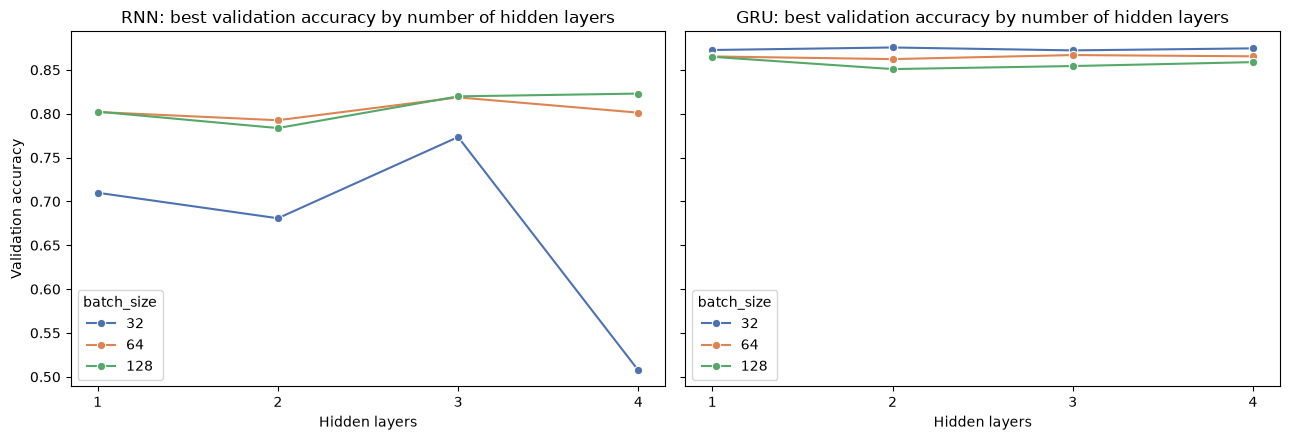

In [22]:
fig, axes = plt.subplots(1, 2, figsize = (13, 4.5), sharey = True)
for ax, model_type in zip(axes, model_types):
    data = best_per_run[best_per_run["model"] == model_type]
    sns.lineplot(data = data, x = "hidden_layers", y = "val_accuracy", hue = "batch_size", marker = "o", palette = "deep", ax = ax)
    ax.set_title(f"{model_type}: best validation accuracy by number of hidden layers")
    ax.set_xticks(layer_options)
    ax.set_xlabel("Hidden layers")
    ax.set_ylabel("Validation accuracy")
plt.tight_layout()
plt.show()

In [23]:
results.groupby(["model", "hidden_layers"])[["val_accuracy"]].max().join(
    results[results["epochs"] == max_epochs].groupby(["model", "hidden_layers"])[["training_time"]].mean().rename(columns = {"training_time": "avg time for 8 epochs (s)"})).round(4)

val_accuracy  avg time for 8 epochs (s)
model hidden_layers                                         
GRU   1                    0.8727                   186.7528
      2                    0.8755                   383.1099
      3                    0.8722                   582.8727
      4                    0.8745                   770.7600
RNN   1                    0.8024                    72.2294
      2                    0.7926                   136.3641
      3                    0.8198                   204.0854
      4                    0.8230                   270.2367

#### Effect of the batch size

In [24]:
results.groupby(["model", "batch_size"])[["val_accuracy"]].max().join(
    results[results["epochs"] == max_epochs].groupby(["model", "batch_size"])[["training_time"]].mean().rename(columns = {"training_time": "avg time for 8 epochs (s)"})).round(4)

val_accuracy  avg time for 8 epochs (s)
model batch_size                                         
GRU   32                0.8755                   592.4379
      64                0.8669                   450.4591
      128               0.8649                   399.7245
RNN   32                0.7734                   226.5671
      64                0.8186                   161.8603
      128               0.8230                   123.7592

#### Effect of the number of epochs

These plots show the training and validation accuracy and loss at each epoch for the 2 layer models with a batch size of 64. If the training accuracy keeps going up while the validation accuracy stops or drops, and the validation loss starts going up, the model is overfitting.

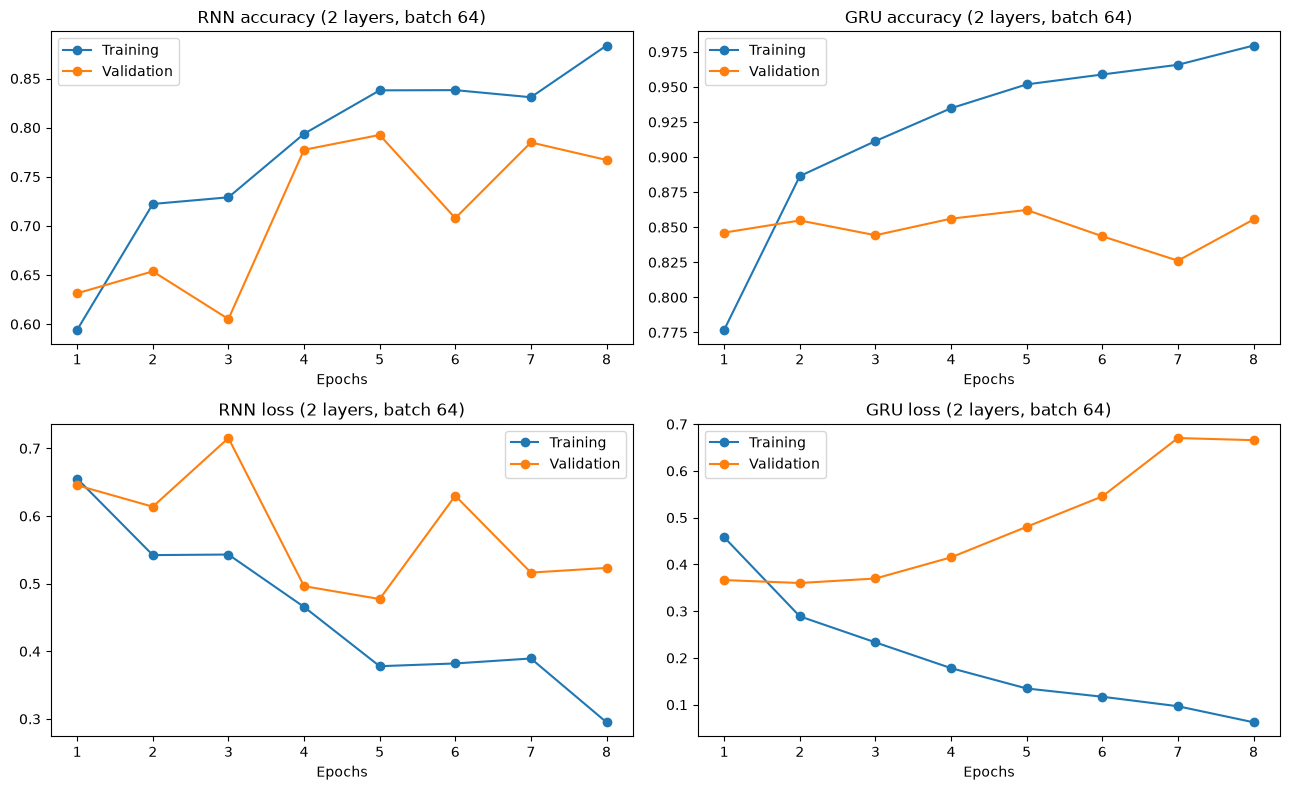

In [25]:
fig, axes = plt.subplots(2, 2, figsize = (13, 8))
for col, model_type in enumerate(model_types):
    data = results[(results["model"] == model_type) & (results["hidden_layers"] == 2) & (results["batch_size"] == 64)]

    axes[0, col].plot(data["epochs"], data["accuracy"], marker = "o", label = "Training")
    axes[0, col].plot(data["epochs"], data["val_accuracy"], marker = "o", label = "Validation")
    axes[0, col].set_title(f"{model_type} accuracy (2 layers, batch 64)")
    axes[0, col].set_xlabel("Epochs")
    axes[0, col].legend()

    axes[1, col].plot(data["epochs"], data["loss"], marker = "o", label = "Training")
    axes[1, col].plot(data["epochs"], data["val_loss"], marker = "o", label = "Validation")
    axes[1, col].set_title(f"{model_type} loss (2 layers, batch 64)")
    axes[1, col].set_xlabel("Epochs")
    axes[1, col].legend()
plt.tight_layout()
plt.show()

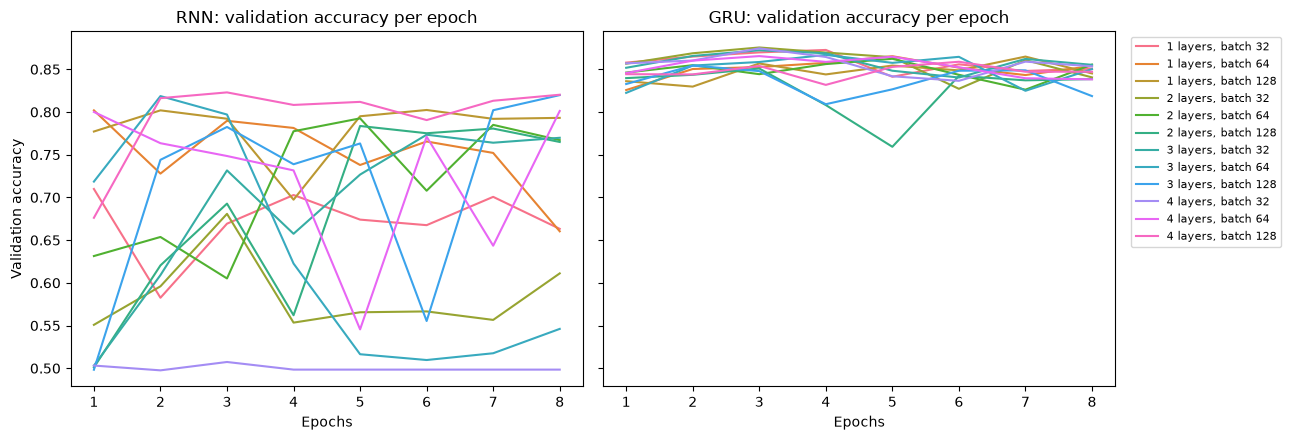

In [26]:
#Validation accuracy at every epoch for every run
fig, axes = plt.subplots(1, 2, figsize = (13, 4.5), sharey = True)
for ax, model_type in zip(axes, model_types):
    data = results[results["model"] == model_type].copy()
    data["run"] = data["hidden_layers"].astype(str) + " layers, batch " + data["batch_size"].astype(str)
    sns.lineplot(data = data, x = "epochs", y = "val_accuracy", hue = "run", ax = ax, legend = (model_type == "GRU"))
    ax.set_title(f"{model_type}: validation accuracy per epoch")
    ax.set_xlabel("Epochs")
    ax.set_ylabel("Validation accuracy")
axes[1].legend(bbox_to_anchor = (1.02, 1), loc = "upper left", fontsize = 8)
plt.tight_layout()
plt.show()

In [27]:
#How many runs overfit, meaning the validation loss at 8 epochs is higher than its lowest point
overfit = results.groupby(["model", "hidden_layers", "batch_size"]).apply(
    lambda d: pd.Series({"lowest_val_loss_epoch": int(d.loc[d["val_loss"].idxmin(), "epochs"]),
                         "train_acc_at_8": d["accuracy"].iloc[-1],
                         "val_acc_at_8": d["val_accuracy"].iloc[-1]}), include_groups = False)
overfit["gap_at_8"] = overfit["train_acc_at_8"] - overfit["val_acc_at_8"]
overfit.round(4)

lowest_val_loss_epoch  train_acc_at_8  \
model hidden_layers batch_size                                          
GRU   1             32                            2.0          0.9873   
                    64                            3.0          0.9830   
                    128                           3.0          0.9556   
      2             32                            2.0          0.9898   
                    64                            2.0          0.9795   
                    128                           1.0          0.9494   
      3             32                            2.0          0.9885   
                    64                            3.0          0.9806   
                    128                           2.0          0.9599   
      4             32                            2.0          0.9898   
                    64                            3.0          0.9693   
                    128                           3.0          0.9484   
RNN   1             32                            1.0          0.8855   
                    64                            1.0          0.8967   
                    128                           2.0          0.9967   
      2             32                            2.0          0.8876   
                    64                            5.0          0.8836   
                    128                           5.0          0.9493   
      3             32                            6.0          0.8203   
                    64                            2.0          0.5409   
                    128                           8.0          0.8658   
      4             32                            5.0          0.5049   
                    64                            8.0          0.8256   
                    128                           2.0          0.8852   

                                val_acc_at_8  gap_at_8  
model hidden_layers batch_size                          
GRU   1             32                0.8508    0.1365  
                    64                0.8539    0.1291  
                    128               0.8451    0.1105  
      2             32                0.8405    0.1492  
                    64                0.8555    0.1240  
                    128               0.8385    0.1109  
      3             32                0.8552    0.1333  
                    64                0.8502    0.1304  
                    128               0.8186    0.1413  
      4             32                0.8535    0.1363  
                    64                0.8382    0.1311  
                    128               0.8472    0.1013  
RNN   1             32                0.6632    0.2223  
                    64                0.6603    0.2364  
                    128               0.7931    0.2035  
      2             32                0.6111    0.2765  
                    64                0.7671    0.1165  
                    128               0.7649    0.1843  
      3             32                0.7698    0.0505  
                    64                0.5461   -0.0052  
                    128               0.8198    0.0460  
      4             32                0.4984    0.0065  
                    64                0.8012    0.0244  
                    128               0.8202    0.0650

### Best configuration for each model

The best configuration is the one with the highest validation accuracy.

In [28]:
best_configs = results.loc[results.groupby("model")["val_accuracy"].idxmax()].set_index("model")
best_configs.round(4)

,hidden_layers,batch_size,epochs,accuracy,loss,val_accuracy,val_loss,training_time
model,,,,,,,,
GRU,2,32,3,0.9284,0.1957,0.8755,0.3410,174.1635
RNN,4,128,3,0.8561,0.3544,0.8230,0.4198,75.0923


### Final training and test set evaluation

The best RNN and the best GRU are trained one last time with their best number of hidden layers, batch size and epochs, and then evaluated on the test set, which hasn't been used at all until now.

Epoch 1/3


217/217 - 25s - 115ms/step - accuracy: 0.5642 - loss: 0.6777 - val_accuracy: 0.6762 - val_loss: 0.6028


Epoch 2/3


217/217 - 24s - 110ms/step - accuracy: 0.8051 - loss: 0.4472 - val_accuracy: 0.8162 - val_loss: 0.4195


Epoch 3/3


217/217 - 24s - 110ms/step - accuracy: 0.8561 - loss: 0.3544 - val_accuracy: 0.8230 - val_loss: 0.4198



RNN classification report
              precision    recall  f1-score   support

    negative       0.82      0.84      0.83      7410
    positive       0.83      0.82      0.83      7465

    accuracy                           0.83     14875
   macro avg       0.83      0.83      0.83     14875
weighted avg       0.83      0.83      0.83     14875



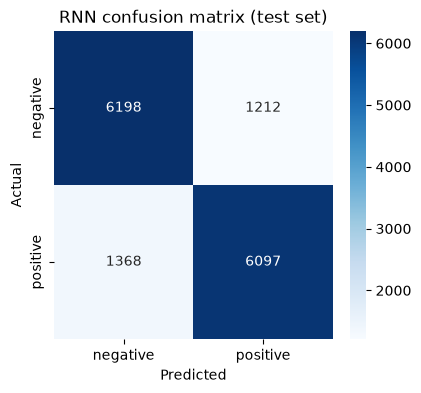

Epoch 1/3


868/868 - 61s - 70ms/step - accuracy: 0.7916 - loss: 0.4403 - val_accuracy: 0.8565 - val_loss: 0.3463


Epoch 2/3


868/868 - 58s - 67ms/step - accuracy: 0.8933 - loss: 0.2737 - val_accuracy: 0.8688 - val_loss: 0.3237


Epoch 3/3


868/868 - 59s - 67ms/step - accuracy: 0.9284 - loss: 0.1957 - val_accuracy: 0.8755 - val_loss: 0.3410



GRU classification report
              precision    recall  f1-score   support

    negative       0.86      0.88      0.87      7410
    positive       0.88      0.86      0.87      7465

    accuracy                           0.87     14875
   macro avg       0.87      0.87      0.87     14875
weighted avg       0.87      0.87      0.87     14875



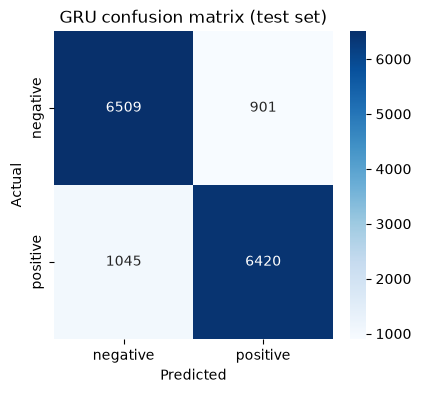

In [29]:
final_results = {}
final_histories = {}

for model_type in model_types:
    config = best_configs.loc[model_type]
    hidden_layers = int(config["hidden_layers"])
    batch_size = int(config["batch_size"])
    epochs = int(config["epochs"])

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    model = build_model(model_type, hidden_layers)
    timer = TimeHistory()

    history = model.fit(x_train, y_train, validation_data = (x_val, y_val),
                        epochs = epochs, batch_size = batch_size,
                        callbacks = [timer], verbose = 2)
    final_histories[model_type] = history.history

    test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose = 0)
    y_pred = (model.predict(x_test, verbose = 0) > 0.5).astype(int).flatten()

    final_results[model_type] = {"hidden_layers": hidden_layers,
                                 "batch_size": batch_size,
                                 "epochs": epochs,
                                 "test_accuracy": test_accuracy,
                                 "test_loss": test_loss,
                                 "precision": precision_score(y_test, y_pred),
                                 "recall": recall_score(y_test, y_pred),
                                 "f1_score": f1_score(y_test, y_pred),
                                 "training_time_s": sum(timer.times),
                                 "time_per_epoch_s": np.mean(timer.times)}

    print(f"\n{model_type} classification report")
    print(classification_report(y_test, y_pred, target_names = ["negative", "positive"]))

    plt.figure(figsize = (4.5, 4))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot = True, fmt = "d", cmap = "Blues",
                xticklabels = ["negative", "positive"], yticklabels = ["negative", "positive"])
    plt.title(f"{model_type} confusion matrix (test set)")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

### Final comparison

In [30]:
final_table = pd.DataFrame(final_results).T
final_table

,hidden_layers,batch_size,epochs,test_accuracy,test_loss,precision,recall,f1_score,training_time_s,time_per_epoch_s
RNN,4.0,128.0,3.0,0.826555,0.418037,0.834177,0.816745,0.825369,72.876273,24.292091
GRU,2.0,32.0,3.0,0.869176,0.345082,0.876929,0.860013,0.868389,177.674563,59.224854


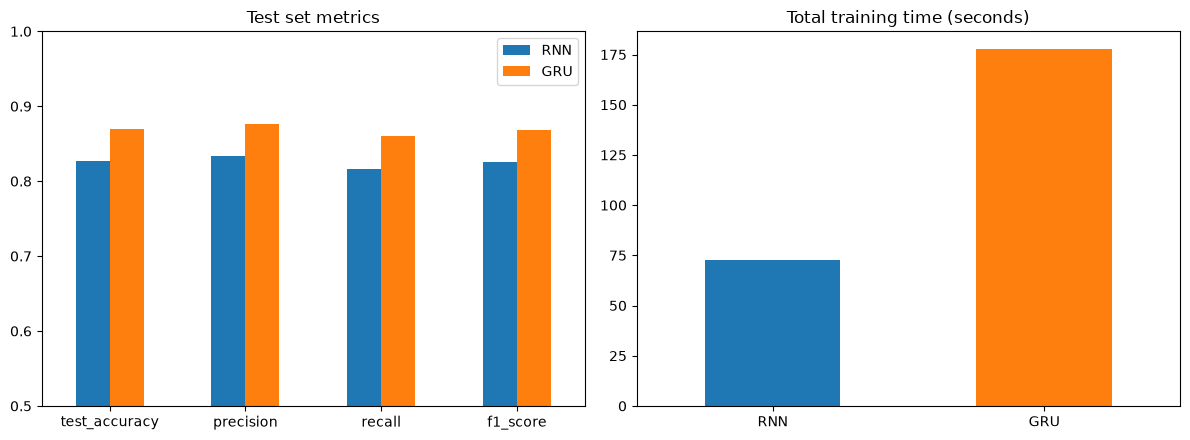

In [31]:
fig, axes = plt.subplots(1, 2, figsize = (12, 4.5))

metrics = ["test_accuracy", "precision", "recall", "f1_score"]
final_table[metrics].astype(float).T.plot(kind = "bar", ax = axes[0])
axes[0].set_title("Test set metrics")
axes[0].set_ylim(0.5, 1)
axes[0].tick_params(axis = "x", rotation = 0)

final_table["training_time_s"].astype(float).plot(kind = "bar", color = ["tab:blue", "tab:orange"], ax = axes[1])
axes[1].set_title("Total training time (seconds)")
axes[1].tick_params(axis = "x", rotation = 0)

plt.tight_layout()
plt.show()

### Summary

The GRU was the better model. Its best configuration (2 hidden layers, batch size 32, 3 epochs) reached 86.9% accuracy on the test set compared to 82.7% for the best RNN (4 hidden layers, batch size 128, 3 epochs), and it also had the lower test loss and the higher precision, recall and F1 score. The RNN was about 2.4 times faster to train, but it was also much less stable. Some RNN runs never learned anything and stayed at 50%, and one collapsed back to 50% after doing well, while every GRU run landed between 85% and 88% validation accuracy.

Adding hidden layers made almost no difference for the GRU and just made it slower. Smaller batches helped the GRU a little, while the RNN needed bigger batches to train steadily. For both models the validation loss was lowest at around 2 to 3 epochs, and after that the training accuracy kept climbing towards 99% while the validation loss went up, which shows the models were overfitting. The full discussion is in the Word report.